# Day 69: K-Means Clustering — Unsupervised Learning

## Objective
- Understand what clustering is (finding groups with no label `y`)
- Learn the K-Means steps: assign, recompute, repeat
- Pick K with the elbow method
- See why `k-means++` initialization is better than random

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Theory
- **Unsupervised learning:** there is no target column, the model looks for structure on its own
- **Clustering:** group similar rows together
- **K-Means** steps:
  1. Pick K starting centroids (centers)
  2. Assign every point to its nearest centroid
  3. Move each centroid to the average of its points
  4. Repeat steps 2-3 until nothing changes
- **Inertia:** the sum of squared distances from each point to its centroid (lower = tighter clusters)
- **Elbow method:** plot inertia vs K and look for the bend where gains slow down
- **k-means++:** a smarter way to choose the starting centroids (spread them out)
- K-Means uses distance, so **scale the features first**

In [2]:
# Load football player stats (per 90 minutes)
df = pd.read_csv("dataset.csv")
features = ["goals_per_90", "assists_per_90", "tackles_per_90", "passes_per_90"]
print(df.shape)
print(df[features].head(3))

(300, 6)
   goals_per_90  assists_per_90  tackles_per_90  passes_per_90
0          0.23            0.28            0.82          25.41
1          0.04            0.09            2.81          36.88
2          0.91            0.10            1.00          18.60


In [3]:
# Put all features on the same scale (mean 0, spread 1)
X = StandardScaler().fit_transform(df[features])
print(X.shape)

(300, 4)


## Example 1: K-Means with k-means++

In [4]:
# We ignore true_position here: K-Means never sees labels
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
df["cluster"] = kmeans.fit_predict(X)

print(df["cluster"].value_counts().sort_index())
print("Inertia:", round(kmeans.inertia_, 1))

cluster
0     90
1    104
2    106
Name: count, dtype: int64
Inertia: 389.0


In [5]:
# What does each cluster look like? Average stats per cluster
profile = df.groupby("cluster")[features].mean().round(2)
print(profile)

         goals_per_90  assists_per_90  tackles_per_90  passes_per_90
cluster                                                             
0                0.53            0.24            0.84          27.65
1                0.14            0.26            1.98          55.18
2                0.05            0.09            3.15          40.48


## Example 2: The algorithm by hand

In [6]:
# Step 1: random starting centroids (3 random players)
rng = np.random.default_rng(1)
centroids = X[rng.choice(len(X), 3, replace=False)]

for i in range(1, 51):
    # Step 2: assign each point to the nearest centroid
    dists = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)
    labels = dists.argmin(axis=1)
    # Step 3: move each centroid to the mean of its points
    new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(3)])
    # Step 4: stop when nothing moves
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

print("Converged after", i, "iterations")
print("Cluster sizes:", np.bincount(labels))

Converged after 8 iterations
Cluster sizes: [ 90 104 106]


## Example 3: The elbow method

K = 1 -> inertia 1200.0
K = 2 -> inertia 640.9
K = 3 -> inertia 389.0
K = 4 -> inertia 334.1
K = 5 -> inertia 282.9
K = 6 -> inertia 259.5


K = 7 -> inertia 237.2


K = 8 -> inertia 218.9


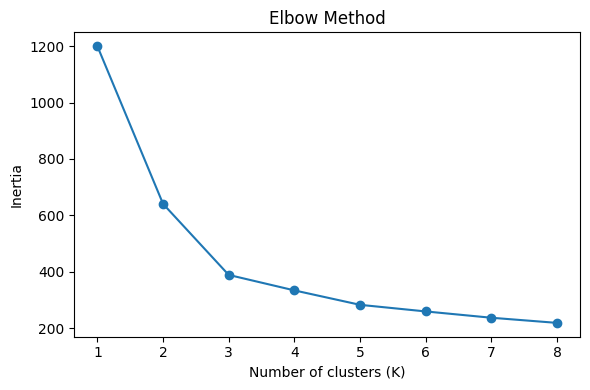

In [7]:
# Try K = 1 to 8 and record the inertia
inertias = []
for k in range(1, 9):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)
    print("K =", k, "-> inertia", round(km.inertia_, 1))

plt.figure(figsize=(6, 4))
plt.plot(range(1, 9), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.tight_layout()
plt.savefig("images/elbow_plot.png", dpi=150)
plt.show()

## Example 4: k-means++ vs random initialization

In [8]:
# One run each, 20 different seeds, so the starting points decide everything
random_inertia, pp_inertia = [], []
for seed in range(20):
    r = KMeans(n_clusters=3, init="random", n_init=1, random_state=seed).fit(X)
    p = KMeans(n_clusters=3, init="k-means++", n_init=1, random_state=seed).fit(X)
    random_inertia.append(r.inertia_)
    pp_inertia.append(p.inertia_)

print("random    -> mean", round(np.mean(random_inertia), 1), "| worst", round(np.max(random_inertia), 1))
print("k-means++ -> mean", round(np.mean(pp_inertia), 1), "| worst", round(np.max(pp_inertia), 1))

random    -> mean 408.5 | worst 584.6
k-means++ -> mean 398.8 | worst 584.6


## Example 5: Do the clusters match real positions?

In [9]:
# true_position was hidden during clustering, so this is a fair check
print(pd.crosstab(df["cluster"], df["true_position"]))

true_position  Defender  Forward  Midfielder
cluster                                     
0                     0       90           0
1                     0        0         104
2                   100        0           6


## Practice Exercise
Run K-Means with `n_clusters=4`. Is the inertia lower or higher than with 3 clusters? Is a lower number always better?

In [10]:
# Your turn: K = 4
km4 = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42).fit(X)
print("K=3 inertia:", round(kmeans.inertia_, 1))
print("K=4 inertia:", round(km4.inertia_, 1))

K=3 inertia: 389.0
K=4 inertia: 334.1


## Mini Challenge
Use the silhouette score (higher = better separated clusters) for K = 2 to 6. Which K wins?

In [11]:
# Silhouette score needs at least 2 clusters
for k in range(2, 7):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X)
    print("K =", k, "-> silhouette", round(silhouette_score(X, km.labels_), 3))

K = 2 -> silhouette 0.452
K = 3 -> silhouette 0.446
K = 4 -> silhouette 0.388
K = 5 -> silhouette 0.34
K = 6 -> silhouette 0.276


## Summary
- Clustering finds groups without any labels
- K-Means: assign to nearest centroid, move centroids, repeat
- Elbow method helps pick K, silhouette score gives a second opinion
- `k-means++` picks smarter starting points
- Always scale features before using K-Means